# Previsão de demanda em e-commerce — Olist

**Pergunta de negócio:** quantos pedidos a operação deve se preparar para atender nas próximas semanas — e qual a melhor forma de planejar essa capacidade?

**Dados:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): cerca de 100 mil pedidos reais e anonimizados de 2016 a 2018, com itens, clientes, vendedores, prazos e avaliações.

**Roteiro**
1. Modelagem dos dados em SQL
2. Análise exploratória: o que move a demanda e a satisfação (11 gráficos)
3. Previsão com backtesting honesto (5 modelos, 8 cortes)
4. Decisão: como planejar a capacidade
5. Limitações e próximos passos

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from olist.data import construir_banco, consulta
from olist.estilo import aplicar
from olist import graficos as g
from olist.previsao import backtest, wape_semanal, wape
aplicar()
construir_banco(forcar=True)
FIG = "../figures/"
def salvar(fig, nome):
    fig.savefig(FIG + nome + ".png")
    return fig

## 1. Modelagem em SQL

Os 8 arquivos da Olist viram um banco SQLite. Duas tabelas analíticas são criadas por SQL versionado na pasta `sql/`:

- `fact_itens` — um registro por item vendido, com categoria, estados do cliente e do vendedor, preço e frete (pedidos cancelados e indisponíveis ficam de fora);
- `pedidos` — um registro por pedido, com prazo prometido, prazo real, atraso e nota da avaliação.

In [2]:
print(consulta('''
SELECT COUNT(DISTINCT order_id) AS pedidos, COUNT(*) AS itens,
       MIN(data_compra) AS primeira_compra, MAX(data_compra) AS ultima_compra,
       ROUND(SUM(preco) / 1e6, 1) AS receita_itens_milhoes
FROM fact_itens''').to_string(index=False))

 pedidos  itens primeira_compra ultima_compra  receita_itens_milhoes
   98199 112101      2016-09-04    2018-09-03                   13.5


In [3]:
print(consulta('''
SELECT order_status AS status, COUNT(*) AS pedidos,
       ROUND(AVG(dias_entrega), 1) AS dias_entrega, ROUND(AVG(nota), 2) AS nota_media
FROM pedidos GROUP BY order_status ORDER BY pedidos DESC''').to_string(index=False))

     status  pedidos  dias_entrega  nota_media
  delivered    96478          12.6        4.14
    shipped     1107           NaN        2.00
   canceled      625          20.4        1.80
unavailable      609           NaN        1.53
   invoiced      314           NaN        1.65
 processing      301           NaN        1.28
    created        5           NaN        1.80
   approved        2           NaN        2.50


## 2. O que move a demanda e a satisfação

### 2.1 A demanda cresceu e mudou de patamar
O volume semanal triplicou ao longo de 2017 e se estabilizou em 2018. Dois choques marcam a série: a Black Friday de 2017 e a greve dos caminhoneiros de maio de 2018.

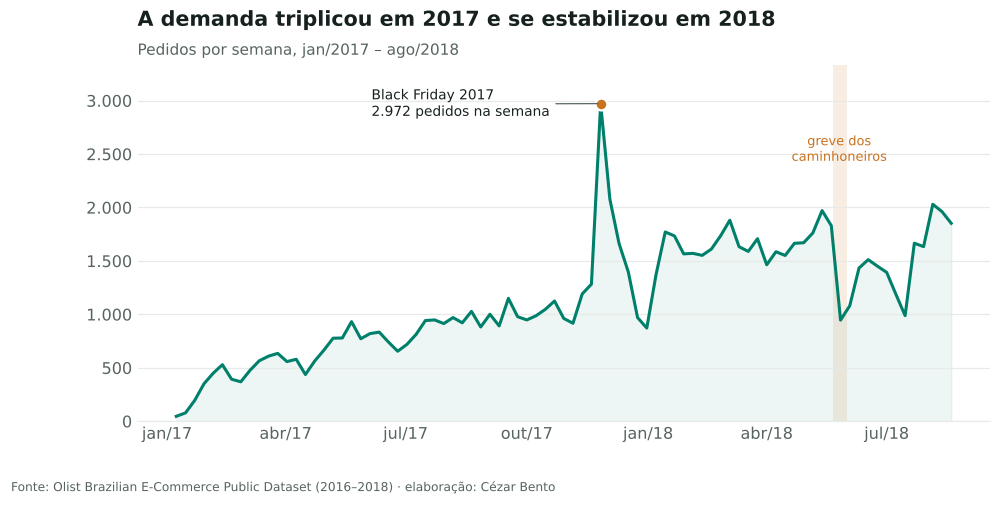

In [4]:
salvar(g.serie_semanal(), "01_serie_semanal");

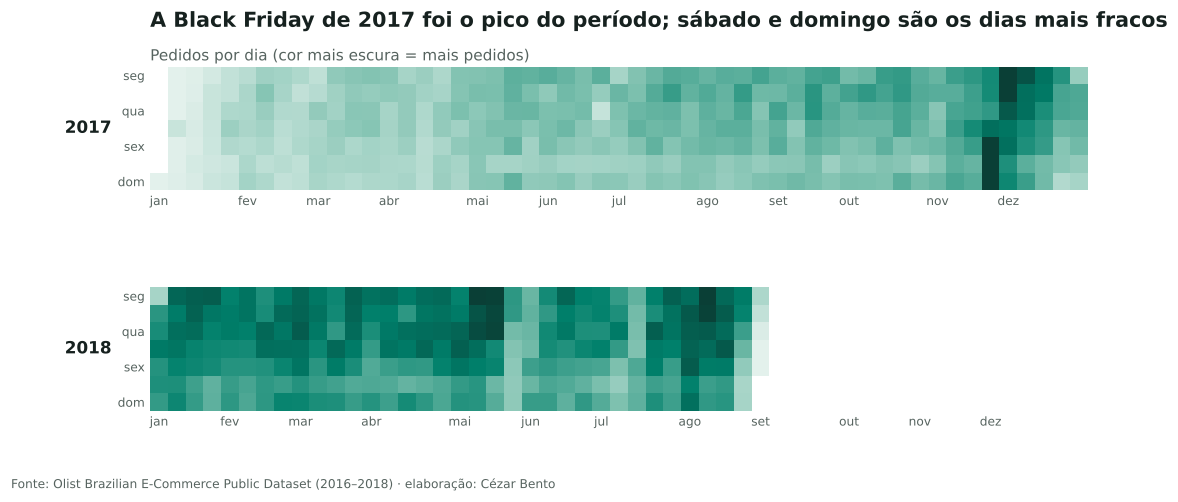

In [5]:
salvar(g.calendario(), "05_calendario");

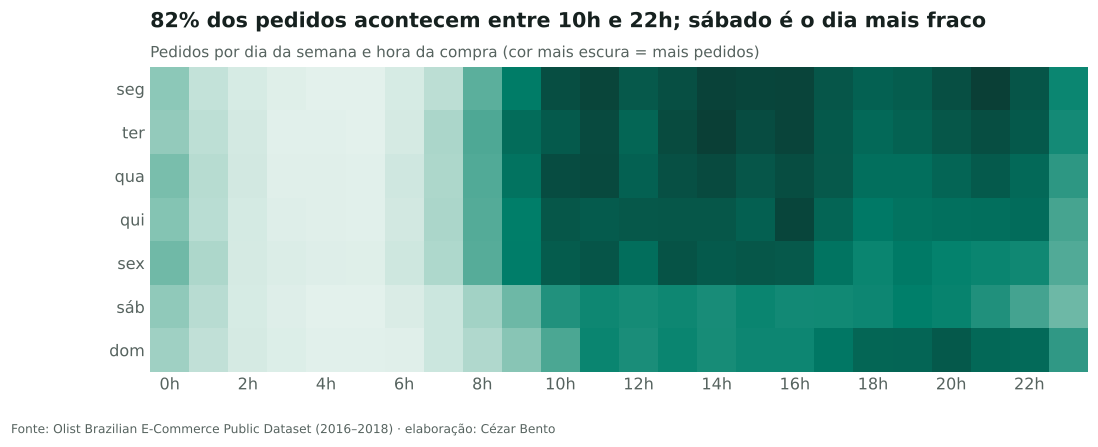

In [6]:
salvar(g.heatmap_hora(), "11_heatmap_hora");

### 2.2 Quem puxou o crescimento
Saúde e beleza cresceu de forma contínua; informática teve um pico no início de 2018 e devolveu. Seis categorias explicam metade do crescimento da receita do 1º semestre.

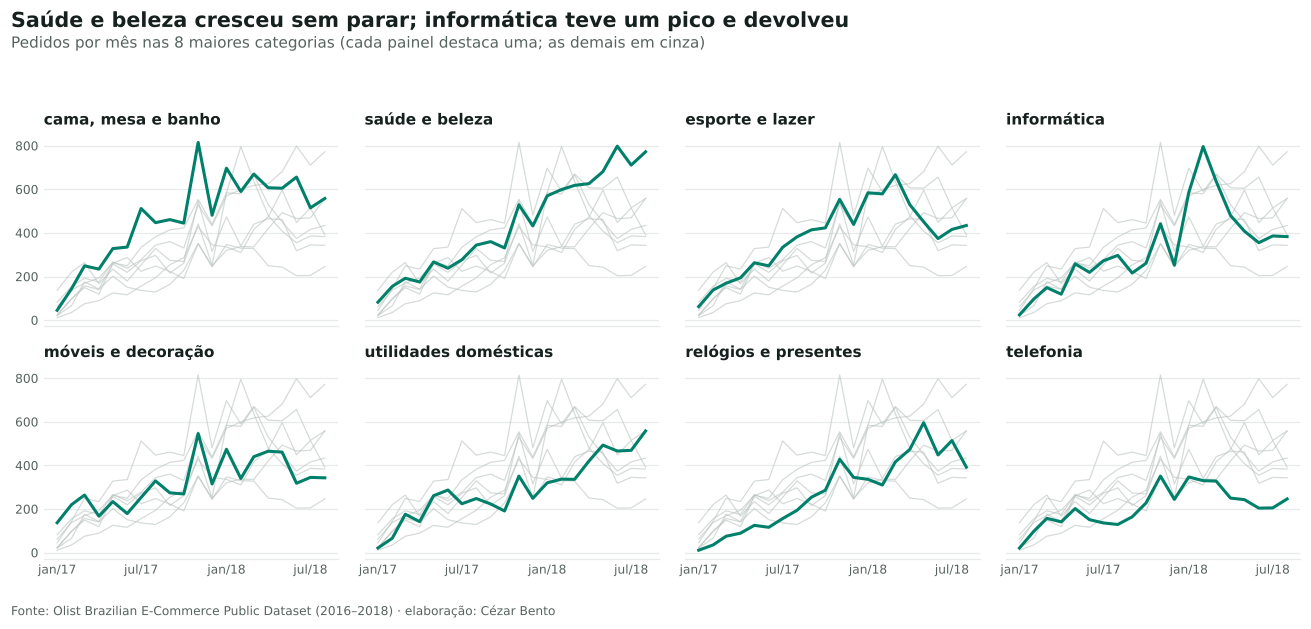

In [7]:
salvar(g.multiplos_categorias(), "06_multiplos_categorias");

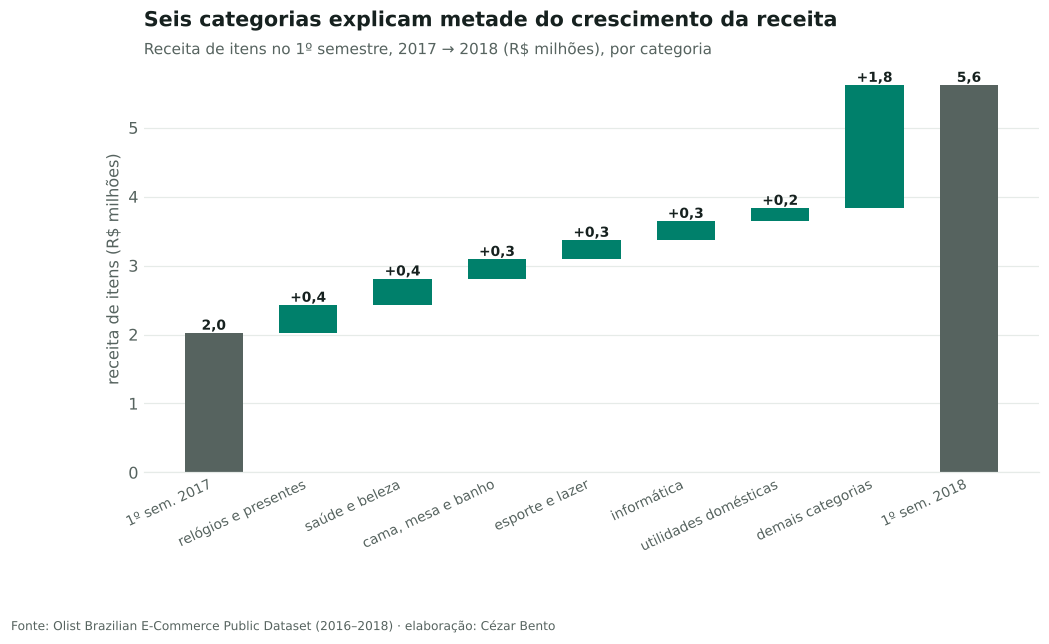

In [8]:
salvar(g.waterfall_receita(), "07_waterfall_receita");

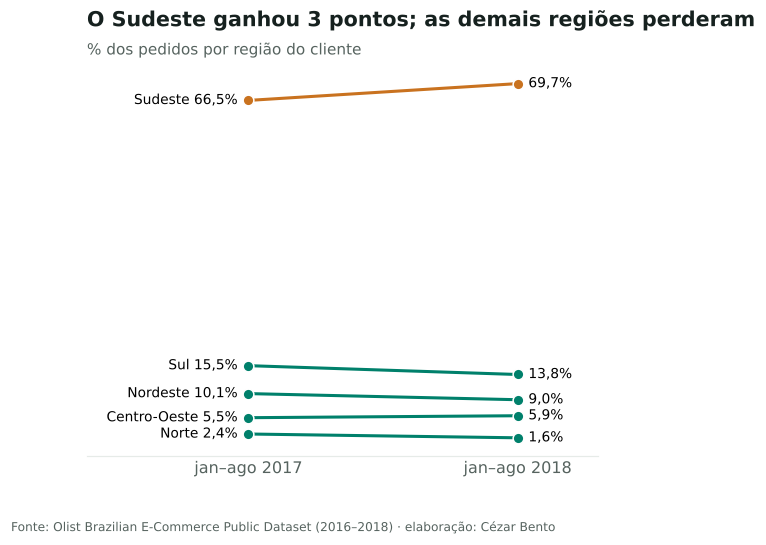

In [9]:
salvar(g.slope_regioes(), "10_slope_regioes");

### 2.3 Logística: prazo, frete e o que o cliente sente
A entrega leva 9 dias em SP e quase 30 no Norte; o frete pesa quase o dobro no Norte. A Olist prometia, em média, 13 dias a mais do que entregava — e o funil mostra que só 55% dos pedidos chegam no prazo **e** viram nota 5.

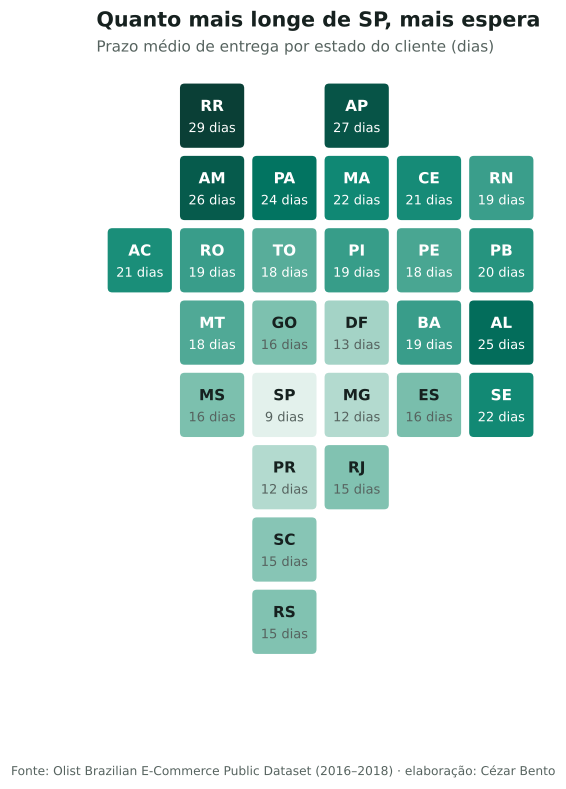

In [10]:
salvar(g.mapa_prazo(), "02_mapa_prazo");

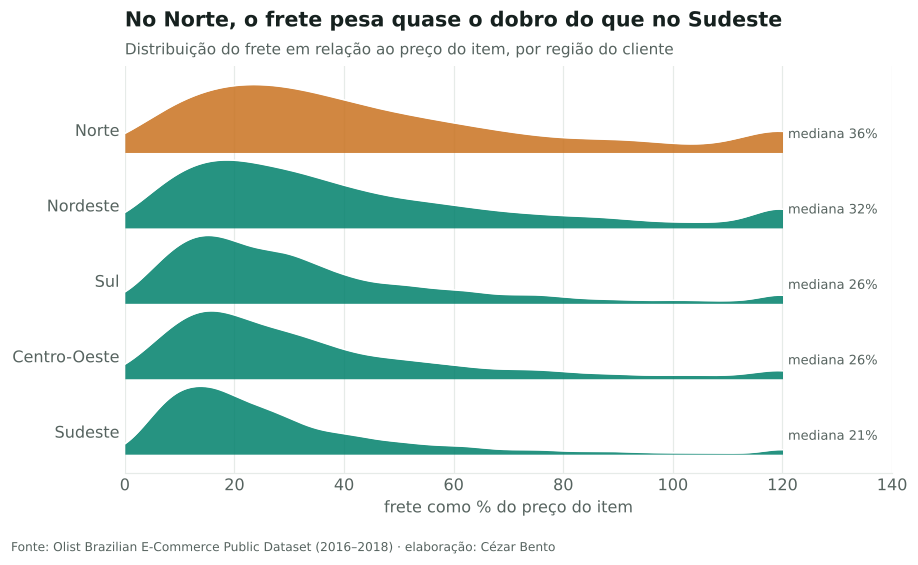

In [11]:
salvar(g.distribuicao_frete(), "09_distribuicao_frete");

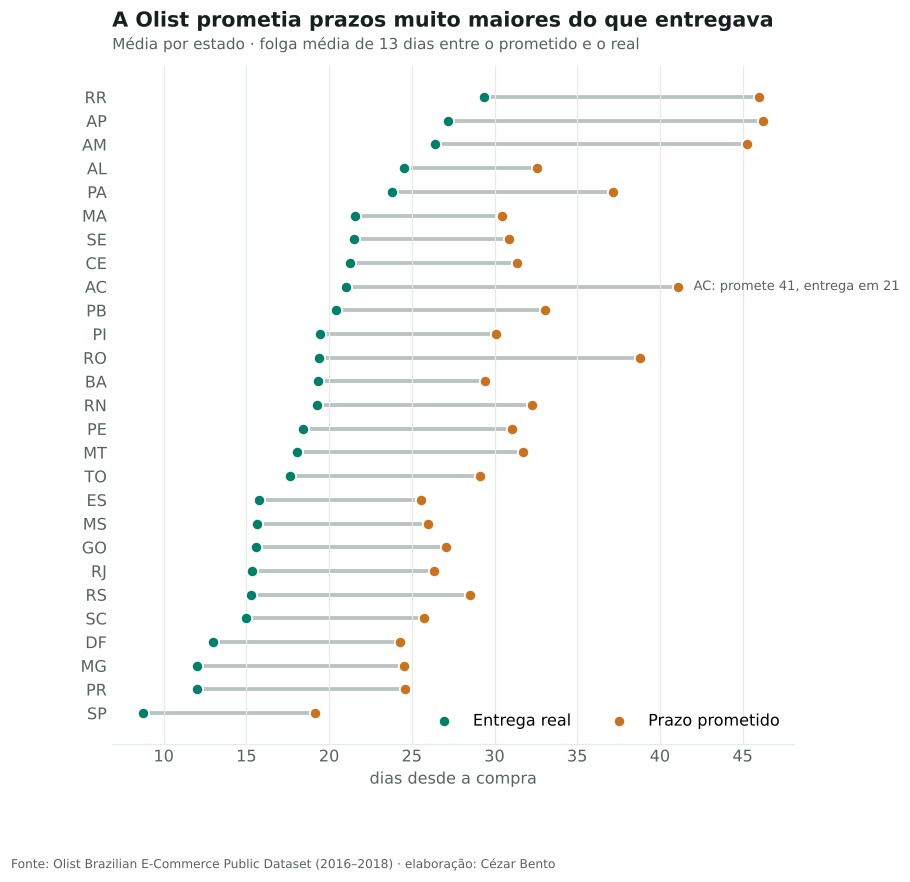

In [12]:
salvar(g.dumbbell_prazo(), "03_dumbbell_prazo");

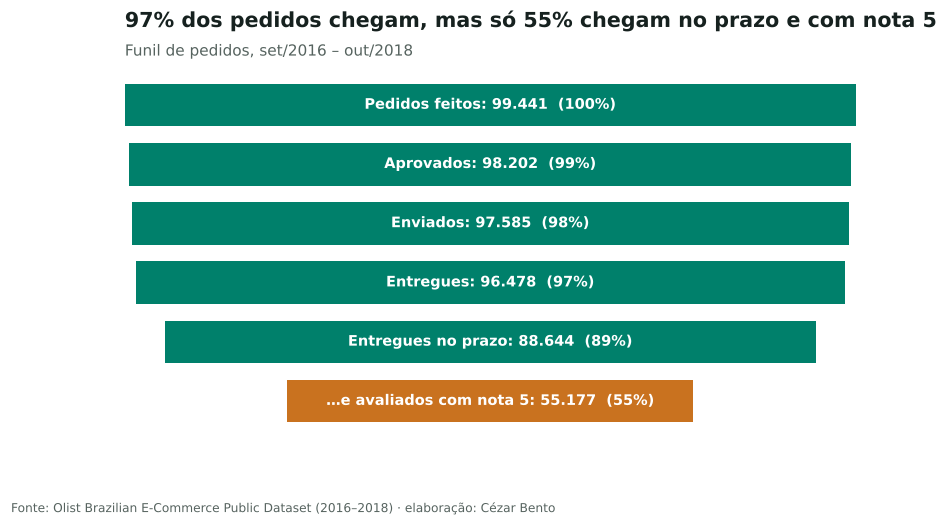

In [13]:
salvar(g.funil(), "08_funil");

### 2.4 O achado que vira decisão
Entregar adiantado quase não muda a nota (4,3 contra 4,2). Atrasar de 4 a 7 dias derruba a nota para 2,3. Como a folga média é de 13 dias, **há espaço para prometer prazos mais curtos** — atraindo mais compras — desde que a promessa continue sendo cumprida. É uma hipótese a validar com teste A/B, não uma conclusão causal.

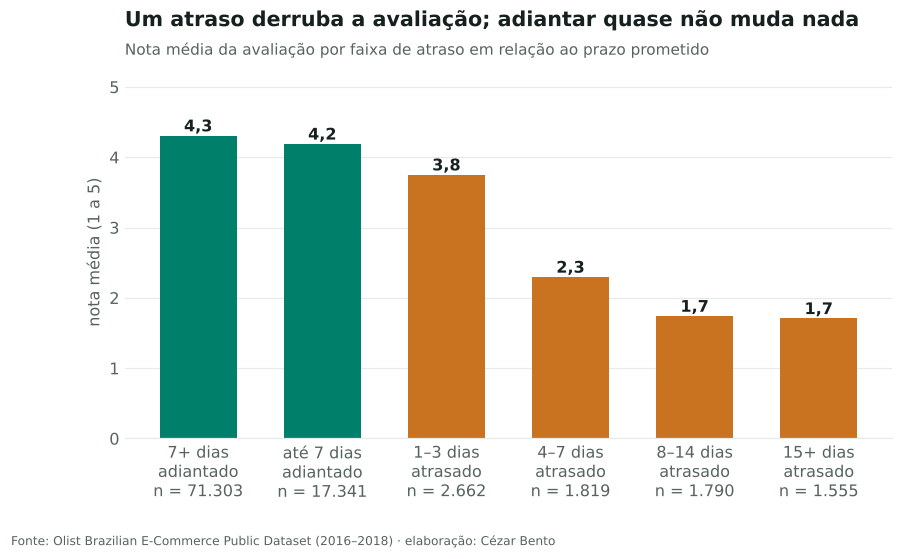

In [14]:
salvar(g.atraso_nota(), "04_atraso_nota");

## 3. Previsão de pedidos

**Alvo:** pedidos por dia, agregados por semana para o planejamento.
**Treino:** a partir de jan/2017 (antes disso o volume é residual).

**Backtest em janelas móveis:** 8 datas de corte em 2018, a cada 28 dias. Em cada corte, cada modelo só vê o passado e prevê os 28 dias seguintes. Nenhuma variável usada no futuro é desconhecida na data do corte.

| Modelo | Ideia |
|---|---|
| Sazonal ingênuo | repete a última semana |
| Média sazonal | média das 4 últimas ocorrências de cada dia da semana |
| Regressão de Poisson | dia da semana + Black Friday + nível recente (em log) |
| Gradient boosting | calendário + nível recente, perda de Poisson |
| Combinação | média dos três anteriores |

**Métrica:** WAPE (erro absoluto ponderado) sobre o total de cada semana — é o erro que importa para escalar equipe e capacidade.

In [15]:
y = g.pedidos_diarios()["2017-01-01":"2018-08-19"]
cortes = pd.date_range("2018-01-07", "2018-07-22", freq="28D")
res, err = backtest(y, cortes)
ws = wape_semanal(err)
tab = ws.pivot(index="corte", columns="modelo", values="wape").mul(100).round(1)
print(tab.to_string())
print()
print((ws.groupby("modelo").wape.mean().mul(100).round(1).sort_values()).to_string())

modelo      Combinação (média dos 3)  Gradient boosting  Média sazonal (4 semanas)  Regressão de Poisson  Sazonal ingênuo
corte                                                                                                                    
2018-01-07                      26.8               14.9                       30.6                  34.9             17.4
2018-02-04                       8.0                8.3                        6.7                  12.6              7.9
2018-03-04                       7.0               17.4                        6.4                   5.5             17.7
2018-04-01                       5.4                7.4                        3.1                   7.6              9.5
2018-04-29                      22.9               23.6                       21.2                  24.0             19.6
2018-05-27                      14.1               11.0                       18.8                  12.3             30.9
2018-06-24              

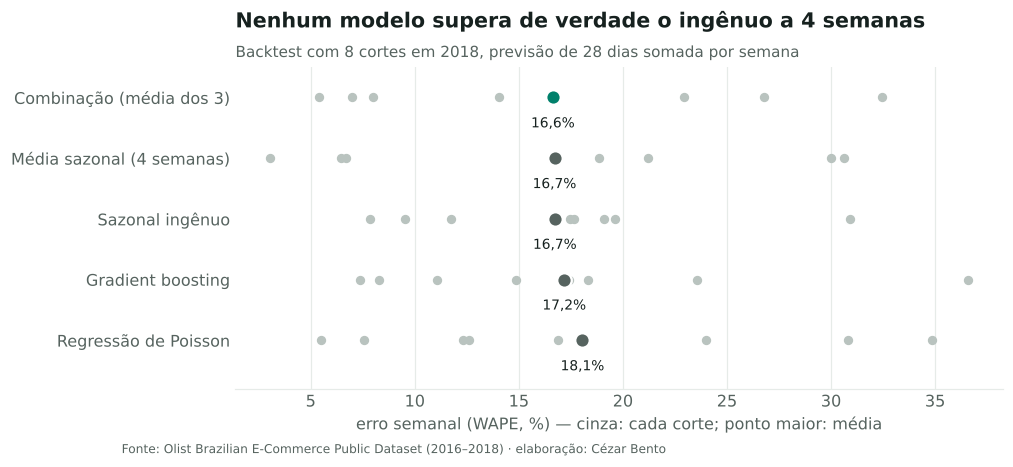

In [16]:
salvar(g.backtest_modelos(ws), "12_backtest_modelos");

**Leitura honesta:** a 4 semanas, nenhum modelo supera de verdade o ingênuo — todos erram cerca de 17%. Há duas razões:
1. a série tem só ~1,5 ano útil, sem um ciclo anual completo para aprender sazonalidade;
2. o erro é dominado por **mudanças de patamar** (pós-Black Friday, greve, julho) que nenhum calendário antecipa.

Complexidade não compra acurácia aqui. A pergunta muda de "qual modelo?" para "com que frequência replanejar?".

## 4. Decisão: replanejar toda semana

In [17]:
cortes7 = pd.date_range("2018-01-07", "2018-08-12", freq="7D")
r7, err7 = backtest(y, cortes7, horizonte=7)
sem = err7[err7.modelo == "Sazonal ingênuo"].groupby("corte")[["real", "prev"]].sum()
erro_1s = wape(sem.real, sem.prev)
erro_4s = ws.groupby("modelo").wape.mean().min()
print(f"Prever 4 semanas à frente (melhor modelo): {erro_4s:.1%}")
print(f"Replanejar toda semana (repetir a última semana): {erro_1s:.1%}")
print(f"Redução do erro: {1 - erro_1s / erro_4s:.0%}")

Prever 4 semanas à frente (melhor modelo): 16.6%
Replanejar toda semana (repetir a última semana): 11.0%
Redução do erro: 34%


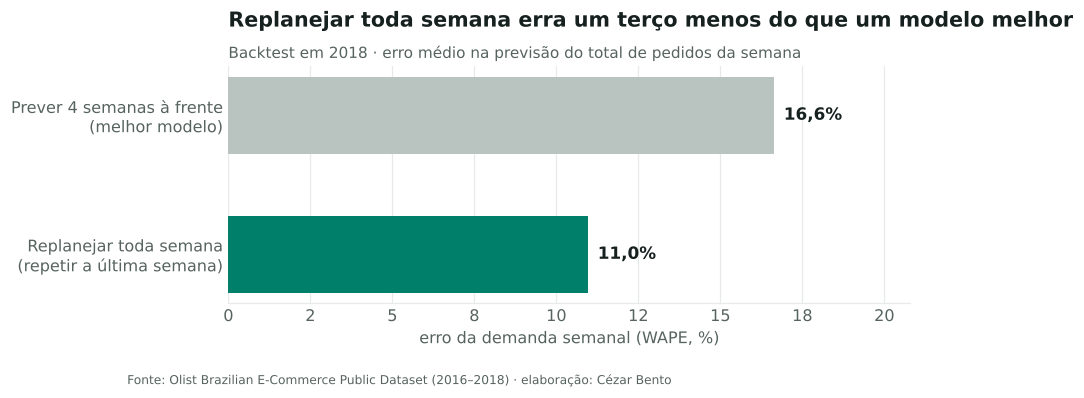

In [18]:
salvar(g.cadencia(erro_4s, erro_1s), "13_cadencia");

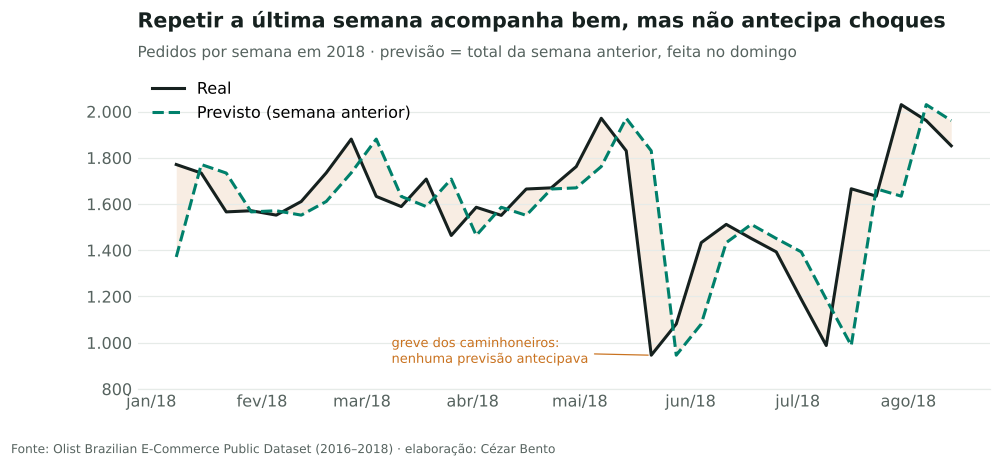

In [19]:
salvar(g.previsto_real(err7), "14_previsto_real");

**Recomendação:** usar a previsão de 4 semanas só como **teto de planejamento** (contratos, escalas longas) e ajustar a capacidade **toda semana** com o dado mais recente — o erro cai de cerca de 17% para 11%.

Testei também colocar uma margem de segurança pelo quantil histórico do erro (estoque-jornaleiro, com custo de faltar 3× o de sobrar). Ela **não pagou**: como o erro muda de sinal entre os regimes, a margem aprendida no período de crescimento sobra no período estável. Ver `src/olist/previsao.py::planejamento`.

## 5. Limitações e próximos passos

- **Histórico curto:** com mais de dois anos seria possível estimar a sazonalidade anual (Natal, Dia das Mães) de forma confiável.
- **Choques externos:** a greve de 2018 é imprevisível pelo calendário; um sistema real monitoraria o erro diário e dispararia replanejamento quando ele saísse da faixa.
- **Granularidade:** o próximo passo é prever por categoria e estado (para alocar estoque e transporte), com modelos hierárquicos e reconciliação.
- **Prazo prometido:** o achado da seção 2.4 pede um teste A/B de promessa de prazo mais curta antes de qualquer mudança.